In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from tqdm import tqdm
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

In [9]:
df = pd.read_csv('heart.csv')
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [4]:
X,y = df.drop('target',axis=1),df['target']
X_train,X_test,y_train,y_test = train_test_split(X,y,random_state=26,test_size=0.3,stratify=y)

In [7]:
depths = [None,2,3,4,5,6,7]
min_split = [2,5,10,20,50]
min_leaf = [1,5,10,20,50]
scores = []
for d in tqdm(depths):
    for s in min_split:
        for f in min_leaf:
            dtc = DecisionTreeClassifier(random_state=26,max_depth=d,min_samples_split=s,min_samples_leaf=f)
            dtc.fit(X_train,y_train)
            y_pred = dtc.predict(X_test)
            scores.append([d,s,f,accuracy_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores,columns=['Depth','Min_sample_splits','Min_sample_leaf','Accuracy'])
df_scores.sort_values(by='Accuracy',ascending=False)

100%|██████████| 7/7 [00:00<00:00,  7.66it/s]


,Depth,Min_sample_splits,Min_sample_leaf,Accuracy
111,5.0,10,5,0.813187
106,5.0,5,5,0.813187
101,5.0,2,5,0.813187
161,7.0,10,5,0.802198
1,NaN,2,5,0.802198
...,...,...,...,...
143,6.0,20,20,0.670330
158,7.0,5,20,0.670330
153,7.0,2,20,0.670330
163,7.0,10,20,0.670330


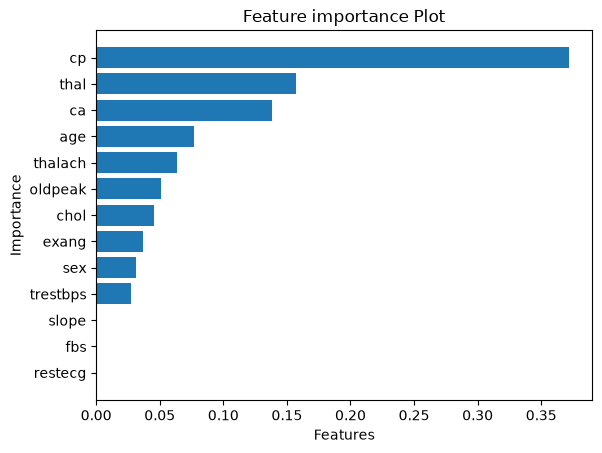

In [13]:
best_tree = DecisionTreeClassifier(random_state=26,max_depth=5,min_samples_split=10,min_samples_leaf=5)
best_tree.fit(X,y)
df_imp = pd.DataFrame(
    {'features':list(X.columns),
    'importance' : best_tree.feature_importances_}
                     )
df_imp.sort_values('importance',inplace=True)
plt.barh(df_imp['features'],df_imp['importance'])
plt.title('Feature importance Plot')
plt.xlabel('Features')
plt.ylabel('Importance')
plt.show()